<a href="https://colab.research.google.com/github/denverkim/BA_FALL2026/blob/main/LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 로지스틱 회귀분석

In [3]:
# logit_train.csv 파일을 불러온 후 statsmodels를 이용해 로지스틱 회귀모델을 만들고, 합격 여부를 예측하시오.

import pandas as pd

train = pd.read_csv('/content/logit_train.csv')
train = train.drop('Unnamed: 0', axis=1)
train.head()

,gmat,gpa,work_experience,admitted
0,780,4.0,3,1
1,750,3.9,4,1
2,690,3.3,3,0
3,710,3.7,5,1
4,680,3.9,4,0


In [4]:
# gmat, gpa, work_experience를 입력 변수 X로 설정
x_train = train.drop('admitted', axis=1)
x_train.head()

,gmat,gpa,work_experience
0,780,4.0,3
1,750,3.9,4
2,690,3.3,3
3,710,3.7,5
4,680,3.9,4


In [5]:
# admitted를 정답 변수 Y로 설정
y_train = train['admitted']
y_train.head()

,admitted
0,1
1,1
2,0
3,1
4,0


In [7]:
# statsmodels를 이용해 로지스틱 회귀모델 학습
import statsmodels.api as sm

logit = sm.Logit(y_train, sm.add_constant(x_train))
result = logit.fit()
result.summary()

Optimization terminated successfully.
         Current function value: 0.214131
         Iterations 8


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               admitted   No. Observations:                   40
Model:                          Logit   Df Residuals:                       36
Method:                           MLE   Df Model:                            3
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.6905
Time:                        07:28:56   Log-Likelihood:                -8.5652
converged:                       True   LL-Null:                       -27.676
Covariance Type:            nonrobust   LLR p-value:                 2.537e-08
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const             -22.0233      9.086     -2.424      0.015     -39.831      -4.216
gmat                0.0157      0.015      1.078      0.281      -0.013       0.044
gpa                 2.4545      2.008      1.222      0.222      -1.481       6.390
work_experience     1.0027      0.573      1.749      0.080      -0.121       2.127
===================================================================================
"""

In [8]:
# logit_test.csv를 불러온 후 모델을 평가하시오.
test = pd.read_csv('/content/logit_test.csv')
test = test.drop('Unnamed: 0', axis=1)
test.head()

,gmat,gpa,work_experience,admitted
0,590,2.0,3,0
1,740,3.7,4,1
2,680,3.3,6,1
3,610,2.3,1,0
4,710,3.0,5,1


In [9]:
# x와 y 분리
x_test = test.drop('admitted', axis=1)
y_test = test['admitted']

In [16]:
# 테스트 데이터의 합격 확률 예측
y_pred = result.predict(sm.add_constant(x_test))
y_pred

,0
0,0.007900
1,0.937027
2,0.941616
3,0.003056
4,0.819506


In [17]:
# 예측값을 0 또는 1로 변환
y_pred = list(map(round, result.predict(sm.add_constant(x_test))))
y_pred

[0, 1, 1, 0, 1]

In [28]:
# 실제 합격 여부와 예측 결과 비교
y_test.values

array([0, 1, 1, 0, 1])

<Axes: >

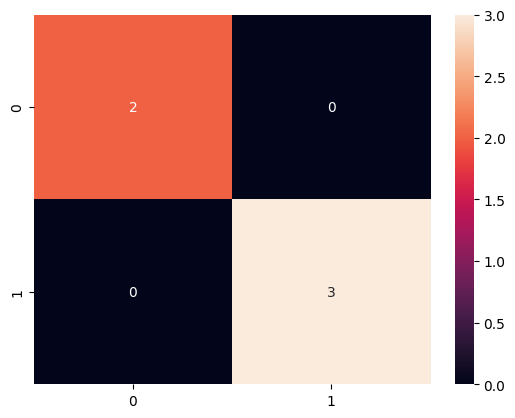

In [22]:
# 혼동행렬
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True)

In [20]:
# 정확도 계산
accuracy_score(y_test, y_pred)

1.0

In [25]:
# 분류 보고서
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [29]:
# logit_train.csv 파일을 불러온 후 sklearn LogisticRegression을 이용해 로지스틱 회귀모델을 만들고, 합격 여부를 예측하시오.
# 로지스틱 회귀 모델 학습
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(x_train, y_train)

LogisticRegression()

In [30]:
# 회귀 계수와 절편 확인
print(model.coef_)
print(model.intercept_)

[[0.02324794 0.7728536  0.99548198]]
[-21.48179059]


In [ ]:
# logit_test.csv를 불러온 후 모델을 평가하시오.
# 테스트 데이터 예측
y_pred = model.predict(x_test)
y_pred

In [35]:
# 예측 정확도 확인
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, y_pred))

1.0


In [36]:
#  교차검증 점수 확인
from sklearn.model_selection import cross_val_score

print(cross_val_score(model, x_train, y_train, cv=5))

[0.75  0.875 0.875 1.    1.   ]


In [40]:
# 교차검증 평균
print(cross_val_score(model, x_train, y_train, cv=5).mean())

0.9


In [39]:
# 교차검증 표준편차
print(cross_val_score(model, x_train, y_train, cv=5).std())

0.09354143466934853
